## Indian Ecommerce Sales Data

### Import the labiries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Import the data 

In [3]:
data=pd.read_csv("indian_ecommerce_sales.csv")

In [4]:
data

,Order_ID,Order_Date,Product_Category,Product_Name,Price,Quantity,Total_Amount,Customer_City,Rating,Payment_Method
0,ORD000001,2023-01-01,Beauty,Pressure Cooker,15718.75,9,141468.75,Hyderabad,4.5,Wallet
1,ORD000002,2023-01-02,Sports,Cricket Bat,28190.06,6,169140.36,Hyderabad,4.4,Cash on Delivery
2,ORD000003,2023-01-03,Home & Kitchen,Jeans,46670.25,9,420032.25,Hyderabad,4.0,Credit Card
3,ORD000004,2023-01-04,Sports,Headphones,15639.98,9,140759.82,Indore,3.9,Wallet
4,ORD000005,2023-01-05,Sports,Jeans,2907.06,7,20349.42,Delhi,4.1,UPI
...,...,...,...,...,...,...,...,...,...,...
9995,ORD009996,2050-05-14,Fashion,Pressure Cooker,34129.77,3,102389.31,Mumbai,3.0,Cash on Delivery
9996,ORD009997,2050-05-15,Home & Kitchen,Face Cream,49151.24,1,49151.24,Chennai,3.9,Cash on Delivery
9997,ORD009998,2050-05-16,Fashion,Pressure Cooker,26853.57,6,161121.42,Mumbai,3.3,Credit Card
9998,ORD009999,2050-05-17,Beauty,Pressure Cooker,10479.86,9,94318.74,Ahmedabad,3.9,Wallet


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          10000 non-null  object 
 1   Order_Date        10000 non-null  object 
 2   Product_Category  10000 non-null  object 
 3   Product_Name      10000 non-null  object 
 4   Price             10000 non-null  float64
 5   Quantity          10000 non-null  int64  
 6   Total_Amount      10000 non-null  float64
 7   Customer_City     10000 non-null  object 
 8   Rating            10000 non-null  float64
 9   Payment_Method    10000 non-null  object 
dtypes: float64(3), int64(1), object(6)
memory usage: 781.4+ KB


In [5]:
data.describe()

,Price,Quantity,Total_Amount,Rating
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,25230.278542,5.069900,127169.192291,3.995340
std,14272.932175,2.571084,103249.665469,0.581591
min,500.460000,1.000000,611.160000,3.000000
25%,12889.080000,3.000000,42538.462500,3.500000
50%,25060.720000,5.000000,97856.895000,4.000000
75%,37563.202500,7.000000,188438.160000,4.500000
max,49991.200000,9.000000,448882.290000,5.000000


In [6]:
data.head()

,Order_ID,Order_Date,Product_Category,Product_Name,Price,Quantity,Total_Amount,Customer_City,Rating,Payment_Method
0,ORD000001,2023-01-01,Beauty,Pressure Cooker,15718.75,9,141468.75,Hyderabad,4.5,Wallet
1,ORD000002,2023-01-02,Sports,Cricket Bat,28190.06,6,169140.36,Hyderabad,4.4,Cash on Delivery
2,ORD000003,2023-01-03,Home & Kitchen,Jeans,46670.25,9,420032.25,Hyderabad,4.0,Credit Card
3,ORD000004,2023-01-04,Sports,Headphones,15639.98,9,140759.82,Indore,3.9,Wallet
4,ORD000005,2023-01-05,Sports,Jeans,2907.06,7,20349.42,Delhi,4.1,UPI


In [7]:
data.tail()

,Order_ID,Order_Date,Product_Category,Product_Name,Price,Quantity,Total_Amount,Customer_City,Rating,Payment_Method
9995,ORD009996,2050-05-14,Fashion,Pressure Cooker,34129.77,3,102389.31,Mumbai,3.0,Cash on Delivery
9996,ORD009997,2050-05-15,Home & Kitchen,Face Cream,49151.24,1,49151.24,Chennai,3.9,Cash on Delivery
9997,ORD009998,2050-05-16,Fashion,Pressure Cooker,26853.57,6,161121.42,Mumbai,3.3,Credit Card
9998,ORD009999,2050-05-17,Beauty,Pressure Cooker,10479.86,9,94318.74,Ahmedabad,3.9,Wallet
9999,ORD010000,2050-05-18,Home & Kitchen,Smartphone,22497.46,5,112487.30,Hyderabad,5.0,Wallet


### Data cleaning

In [8]:
# check the null values
data.isnull().sum()

Order_ID            0
Order_Date          0
Product_Category    0
Product_Name        0
Price               0
Quantity            0
Total_Amount        0
Customer_City       0
Rating              0
Payment_Method      0
dtype: int64

In [9]:
data.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [10]:
data.duplicated().sum()

np.int64(0)

## Analysis the data

## Price by Product_Category

In [11]:
category_price=data.groupby("Product_Category")["Price"].sum().sort_values(ascending=False)
category_price

Product_Category
Fashion           51970991.15
Electronics       51475413.48
Sports            50224432.90
Home & Kitchen    49425210.39
Beauty            49206737.50
Name: Price, dtype: float64

## Quantity sold by Product_Name

In [12]:
Product_Name_Quantity=data.groupby("Product_Name")["Quantity"].sum().sort_values(ascending=False)
Product_Name_Quantity

Product_Name
Pressure Cooker    4564
Mixer              4332
Headphones         4311
Laptop             4302
Cricket Bat        4282
T-shirt            4246
Jeans              4239
Football           4196
Smartphone         4195
Lipstick           4144
Saree              4115
Face Cream         3773
Name: Quantity, dtype: int64

## city wise Product_name Quantity

In [14]:
city_wise_product_name_quantity=data.groupby(["Customer_City","Product_Name"])["Quantity"].sum().sort_values(ascending=False)
city_wise_product_name_quantity

Customer_City  Product_Name   
Pune           Smartphone         658
Ahmedabad      Headphones         647
Delhi          Pressure Cooker    644
Chennai        Jeans              641
Pune           Pressure Cooker    638
                                 ... 
Chennai        Saree              446
Mumbai         Face Cream         443
Indore         Lipstick           441
Delhi          Mixer              440
Bangalore      T-shirt            430
Name: Quantity, Length: 96, dtype: int64

### city wise Product_Category Amount

In [18]:
city_wise_product_category_amount=data.groupby(["Customer_City","Product_Category"])["Total_Amount"].sum().sort_values(ascending=False).head()
city_wise_product_category_amount

Customer_City  Product_Category
Ahmedabad      Fashion             40174894.26
Pune           Beauty              36468902.00
Hyderabad      Home & Kitchen      36181216.87
Delhi          Beauty              35930398.77
Pune           Sports              35474661.57
Name: Total_Amount, dtype: float64

In [19]:
print(data.columns)

Index(['Order_ID', 'Order_Date', 'Product_Category', 'Product_Name', 'Price',
       'Quantity', 'Total_Amount', 'Customer_City', 'Rating',
       'Payment_Method'],
      dtype='object')


In [23]:
data["Total_Sales"] = data["Price"] * data["Quantity"]
data["Total_Sales"]

0       141468.75
1       169140.36
2       420032.25
3       140759.82
4        20349.42
          ...    
9995    102389.31
9996     49151.24
9997    161121.42
9998     94318.74
9999    112487.30
Name: Total_Sales, Length: 10000, dtype: float64

## customer_city wise total_sales

In [26]:
customer_city_sales=data.groupby("Customer_City")["Total_Sales"].sum().sort_values(ascending=False)
customer_city_sales

Customer_City
Pune         1.640415e+08
Delhi        1.628648e+08
Hyderabad    1.618839e+08
Ahmedabad    1.606441e+08
Chennai      1.593927e+08
Indore       1.555732e+08
Mumbai       1.554756e+08
Bangalore    1.518161e+08
Name: Total_Sales, dtype: float64

## payment wise order count

In [33]:
payment_order_count=data.groupby("Payment_Method")["Order_ID"].count().sort_values(ascending=False)
payment_order_count

Payment_Method
Wallet              2573
Credit Card         2496
UPI                 2483
Cash on Delivery    2448
Name: Order_ID, dtype: int64

## product wise average rating

In [32]:
product_category_rating=data.groupby("Product_Category")["Rating"].mean()
product_category_rating

Product_Category
Beauty            3.987038
Electronics       3.973083
Fashion           4.010714
Home & Kitchen    4.010396
Sports            3.996186
Name: Rating, dtype: float64

## Data visulization

## Pie Chart--Payment Method distribution

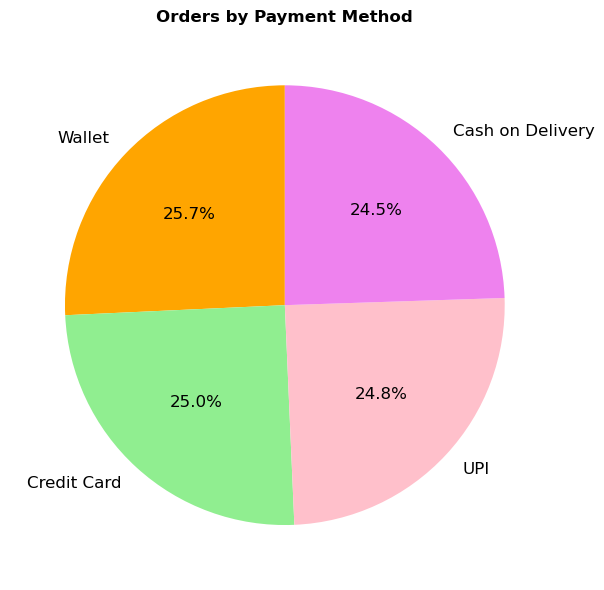

In [54]:
payment_counts=data['Payment_Method'].value_counts()
plt.figure(figsize=(8,6))
plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['orange','lightgreen','pink','violet',],
    explode=(0.04,0),
    textprops={'fontsize': 12}
)
plt.title('Orders by Payment Method',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()        

## Histogram--Product Price distribution

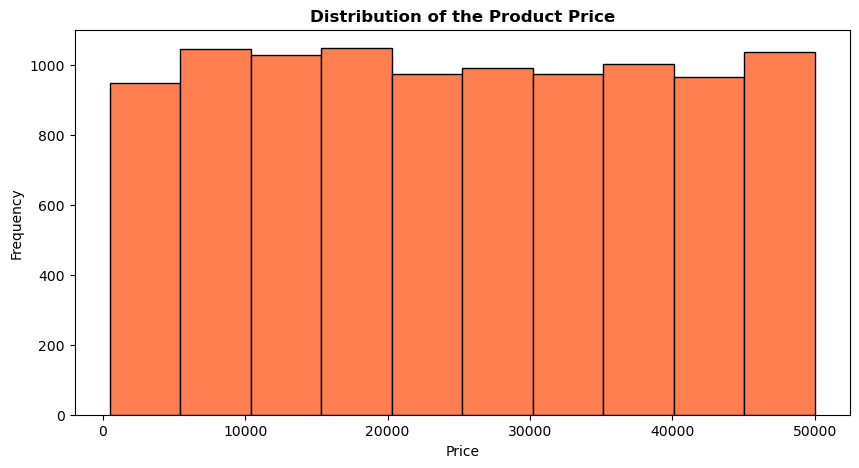

In [49]:
plt.figure(figsize=(10,5))
plt.hist(
    data['Price'],
    bins=10,
    color='coral',
    edgecolor='black'
)   
plt.title('Distribution of the Product Price',fontsize=12,fontweight='bold')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

## Bar Chart--Category wise Total Sales

NameError: name 'bars' is not defined

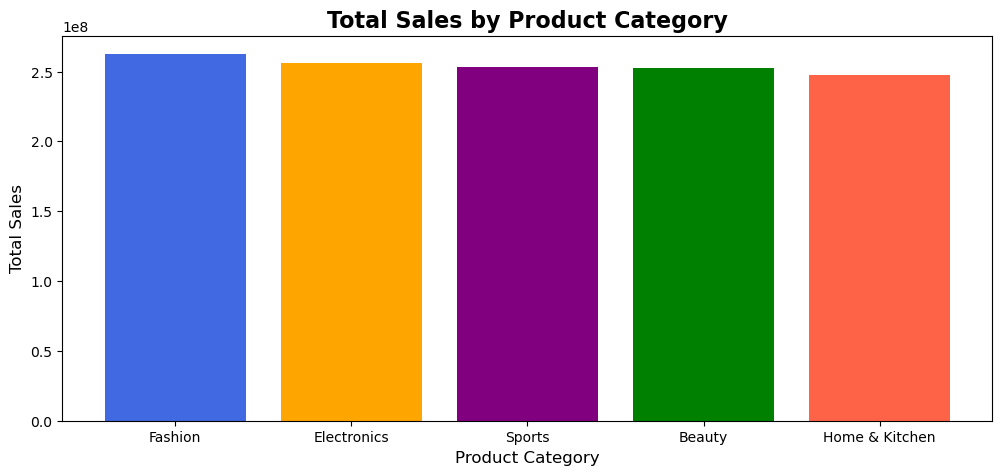

In [55]:
category_sales=data.groupby('Product_Category')['Total_Amount'].sum()
category_sales=category_sales.sort_values(ascending=False)
plt.figure(figsize=(12,5))
plt.bar(
    category_sales.index,
    category_sales.values,
    color=['royalblue','orange','purple','green','tomato','hotpink']
)
plt.title('Total Sales by Product Category',fontsize=16,fontweight='bold')
plt.xlabel('Product Category',fontsize=12)
plt.ylabel('Total Sales',fontsize=12)

plt.bar_label(bars,padding=5,fontsize=11)
plt.tight_layout()
plt.show()

## Pie chart--Customer city distribution

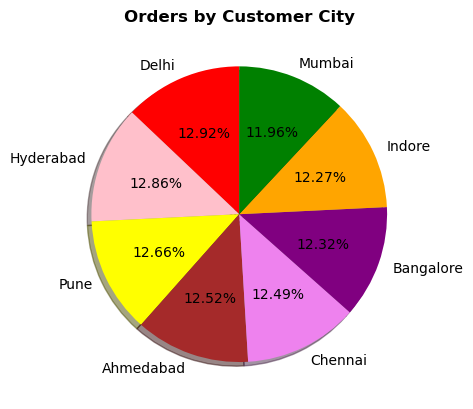

In [70]:
city=data['Customer_City'].value_counts()
colors=['red','pink','yellow','brown','violet','purple','orange','green']
plt.pie(
    city,
    labels=city.index,
    autopct='%1.2f%%',
    colors=colors[:len(city)],
    startangle=90,
    shadow=True
)

plt.title('Orders by Customer City',fontsize=12,fontweight='bold')
plt.show()

## Histogram-- Rating wise Product distribution

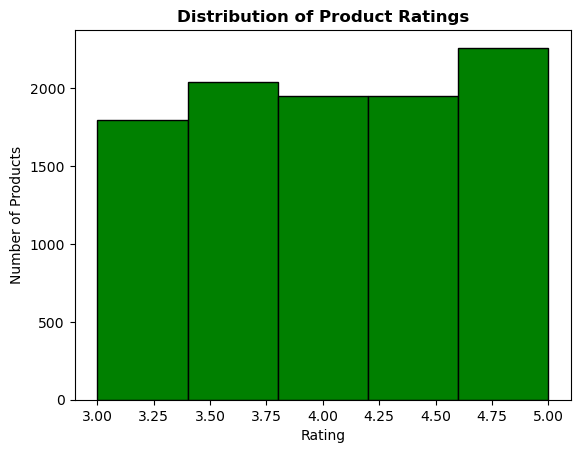

In [73]:
plt.hist(data['Rating'],histtype='bar',bins=5,edgecolor='Black',color='green')

plt.title("Distribution of Product Ratings",fontsize=12,fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

## Bar chart--top 10 Product by Quantity

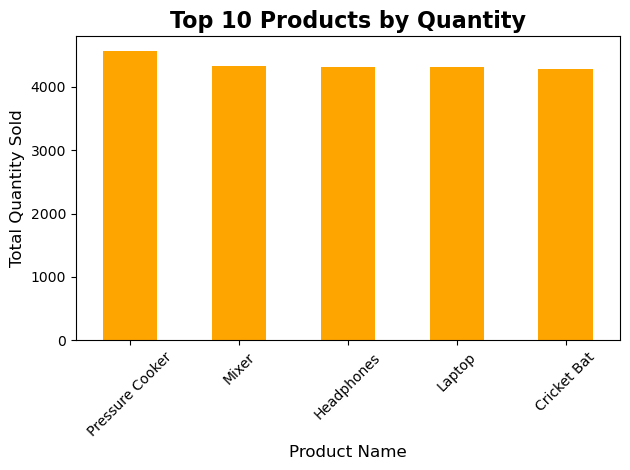

In [6]:
top_product=data.groupby('Product_Name')['Quantity'].sum().sort_values(ascending=False).head()
top_product.plot(kind='bar',color='orange')

plt.title('Top 10 Products by Quantity',fontsize=16,fontweight='bold')
plt.xlabel('Product Name',fontsize=12)
plt.ylabel('Total Quantity Sold',fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()